# 07 — Explainability: SHAP Analysis

**Goal** – Explain what drives predictions in the global and per-creator models
using SHAP (SHapley Additive exPlanations).

Sections:
1. **Global XGBoost** — TreeExplainer on test set, beeswarm plot, top-15 features, dependence plots.
2. **Per-creator SHAP** — feature importance for each creator; Spearman correlation
   between creator-specific and global feature importance ranks.
3. **Stability analysis** — for ~25 sampled creators of different sizes, bootstrap-retrain
   15× and check whether the top-3 features are consistent.
4. **Case studies** — three creators (small / medium / large), labelled Creator A/B/C.

**Key question**: how much do creators differ in *which* features matter,
and are per-creator patterns stable enough to trust?


In [1]:
import sys
if "google.colab" in sys.modules:
    import subprocess, os
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/Shopska/Personalized_analysis_of_social_media.git", "repo"],
        check=True,
    )
    os.chdir("repo")
    subprocess.run(
        ["pip", "install", "-q", "-r", "requirements.txt", "-r", "requirements-dev.txt"],
        check=True,
    )
    subprocess.run(["pip", "install", "-q", "-e", "."], check=True)
    subprocess.run(["python", "scripts/download_data.py"], check=True)


In [2]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Ensure working directory is the project root when opened from notebooks/
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})


In [3]:
import shap
import joblib
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from creator_analytics.config import load_config
from creator_analytics.data import filter_creators, load_raw_table, train_test_split_by_creator
from creator_analytics.features import build_features, FEATURE_DESCRIPTIONS
from creator_analytics.models import (
    prepare_X, TrainedModel, CreatorModel,
    _make_creator_pipe, drop_constant_features,
)
from creator_analytics.targets import build_target, get_nonmonotonic_video_ids
from creator_analytics.utils import set_seed

config = load_config("config/default.yaml")
set_seed(config["seed"])

RAW  = config["paths"]["raw_dir"]
SEED = config["seed"]
FIGS = Path("results/figures")
FIGS.mkdir(parents=True, exist_ok=True)
PC_MODEL_DIR = Path("models/per_creator/RF")

videos        = load_raw_table(RAW, "videos")
creator_daily = load_raw_table(RAW, "creator_daily")
engagement    = load_raw_table(RAW, "engagement_daily")

bad_ids      = get_nonmonotonic_video_ids(engagement)
videos_clean = videos[~videos["video_id"].isin(bad_ids)].reset_index(drop=True)
videos_f     = filter_creators(videos_clean, "author_id",
                                min_videos=config["data"]["min_videos_per_creator"])

train_df, test_df = train_test_split_by_creator(
    videos_f, "author_id", test_size=config["split"]["test_size"], seed=SEED
)
train_ids = set(train_df["video_id"])
test_ids  = set(test_df["video_id"])

feat_path = Path("data/processed/features.parquet")
features = (pd.read_parquet(feat_path) if feat_path.exists()
            else build_features(videos_f, creator_daily, train_video_ids=train_ids))

rel_t = build_target(engagement, videos_f, day=14, mode="relative",
                     train_video_ids=train_ids)
data = (features
        .merge(videos_f[["video_id", "author_id"]], on="video_id")
        .merge(rel_t, on="video_id"))

train_mask = data["video_id"].isin(train_ids)
test_mask  = data["video_id"].isin(test_ids)

X_all        = prepare_X(data.drop(columns=["author_id", "target"]))
X_train      = X_all[train_mask].reset_index(drop=True)
y_train      = data.loc[train_mask, "target"].reset_index(drop=True)
author_train = data.loc[train_mask, "author_id"].reset_index(drop=True)
X_test       = X_all[test_mask].reset_index(drop=True)
y_test       = data.loc[test_mask, "target"].reset_index(drop=True)
author_test  = data.loc[test_mask, "author_id"].reset_index(drop=True)

global_model = TrainedModel.load(Path("models/global_xgb.joblib"))

def _short_label(fname, maxlen=38):
    desc = FEATURE_DESCRIPTIONS.get(fname, fname)
    return desc[:maxlen] if len(desc) > maxlen else desc

print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")
print(f"Global model: {global_model.model_name} | features: {len(global_model.feature_names)}")


Train: 160,492 rows | Test: 40,124 rows
Global model: global_xgb_best | features: 53


## 1. Global XGBoost — SHAP Values on Test Set

`shap.TreeExplainer` computes exact Shapley values for tree ensembles.
Each value gives the contribution of one feature to one prediction
relative to the model's base value (average train prediction).

* **Beeswarm plot** — distribution and direction for top-15 features.
* **Bar chart** — overall importance (mean |SHAP|).


SHAP matrix: (40124, 53)  |  base value: 0.1414

Top 15 global features:


,feature,mean_abs_shap
0,follower_count_log,0.074607
1,sticker_text_len,0.066211
2,duration_log,0.049419
3,joy,0.045742
4,disgust,0.042397
5,desc_len,0.039111
6,video_count_at_publish,0.037220
7,speaking_rate,0.036317
8,days_since_prev_video,0.028936
9,music_selected_from,0.027974


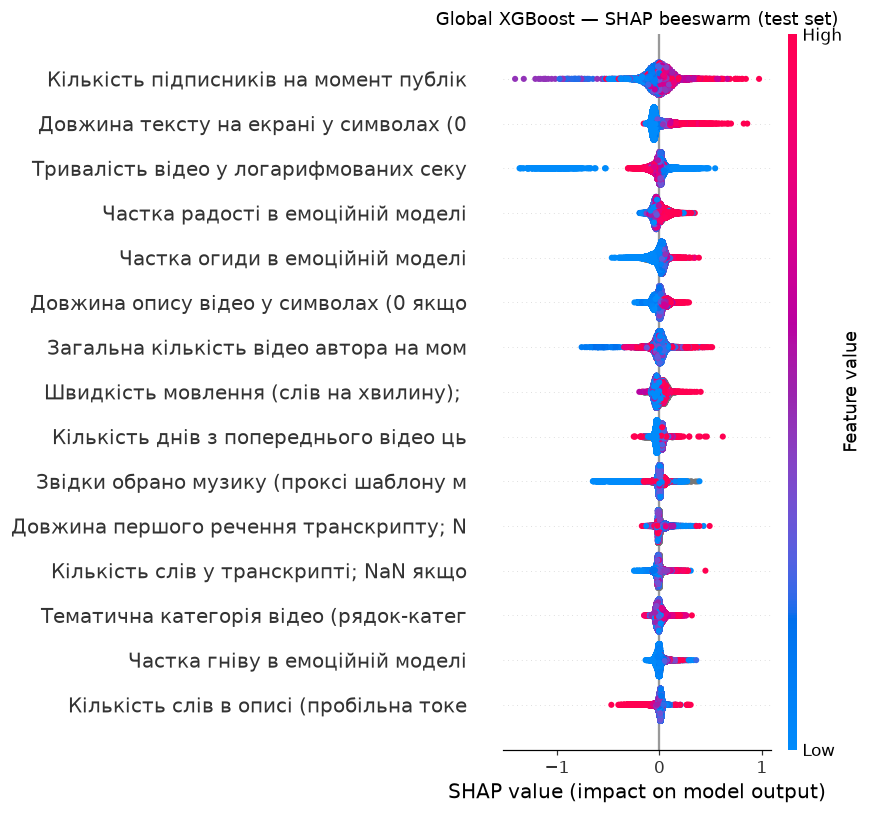

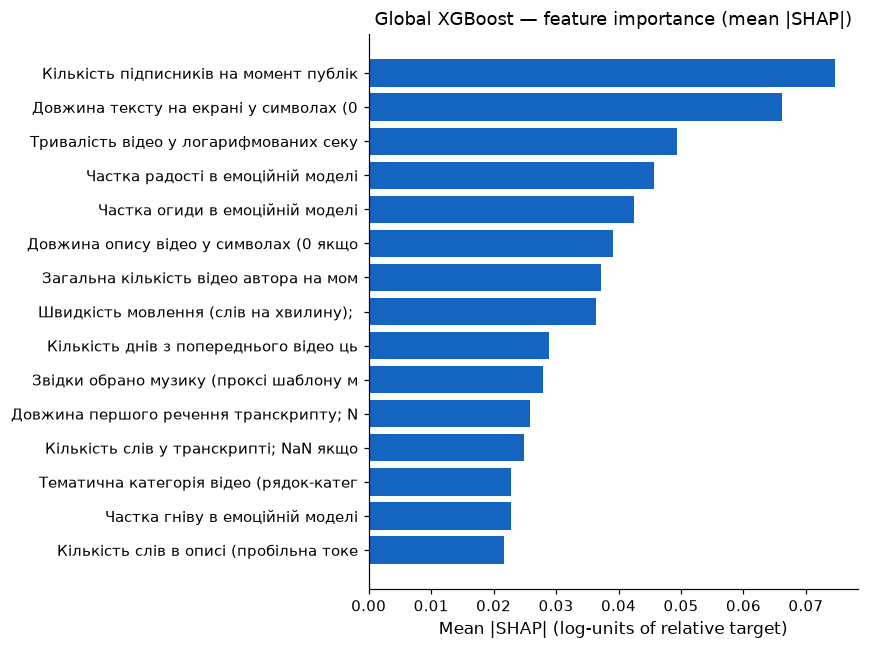

Saved results/shap_global_test.parquet  (40124, 53)


In [4]:
X_test_aligned = X_test[global_model.feature_names]
X_test_enc     = global_model.preprocessor.transform(X_test_aligned)

raw_ct_names    = global_model.preprocessor.get_feature_names_out()
shap_feat_names = [n.split("__", 1)[-1] for n in raw_ct_names]
shap_labels     = [_short_label(fn) for fn in shap_feat_names]

explainer_global = shap.TreeExplainer(global_model.model)
shap_vals_global = explainer_global.shap_values(X_test_enc)
print(f"SHAP matrix: {shap_vals_global.shape}  |  base value: {explainer_global.expected_value:.4f}")

mean_abs_shap = np.abs(shap_vals_global).mean(axis=0)
global_importance = pd.DataFrame({
    "feature":       shap_feat_names,
    "label":         shap_labels,
    "mean_abs_shap": mean_abs_shap,
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

print("\nTop 15 global features:")
display(global_importance.head(15)[["feature", "mean_abs_shap"]])

# Beeswarm
shap.summary_plot(
    shap_vals_global, X_test_enc,
    feature_names=shap_labels, max_display=15, show=False,
)
plt.title("Global XGBoost — SHAP beeswarm (test set)", fontsize=12)
plt.tight_layout()
plt.savefig(FIGS / "nb07_global_shap_beeswarm.png", dpi=120, bbox_inches="tight")
plt.show()

# Bar chart of mean |SHAP|
top15 = global_importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top15["label"], top15["mean_abs_shap"], color="#1565C0")
ax.set_xlabel("Mean |SHAP| (log-units of relative target)", fontsize=11)
ax.set_title("Global XGBoost — feature importance (mean |SHAP|)", fontsize=12)
plt.tight_layout()
plt.savefig(FIGS / "nb07_global_shap_bar.png", dpi=120, bbox_inches="tight")
plt.show()

# Save SHAP matrix
shap_df = pd.DataFrame(shap_vals_global, columns=shap_feat_names)
shap_df.to_parquet("results/shap_global_test.parquet", index=False)
print(f"Saved results/shap_global_test.parquet  {shap_df.shape}")


### 1.2 Dependence Plots — Top 5 Features

A dependence plot shows how the SHAP value for one feature varies with its
raw magnitude.  The dot colour is chosen automatically as the most correlated
other feature (interaction proxy).


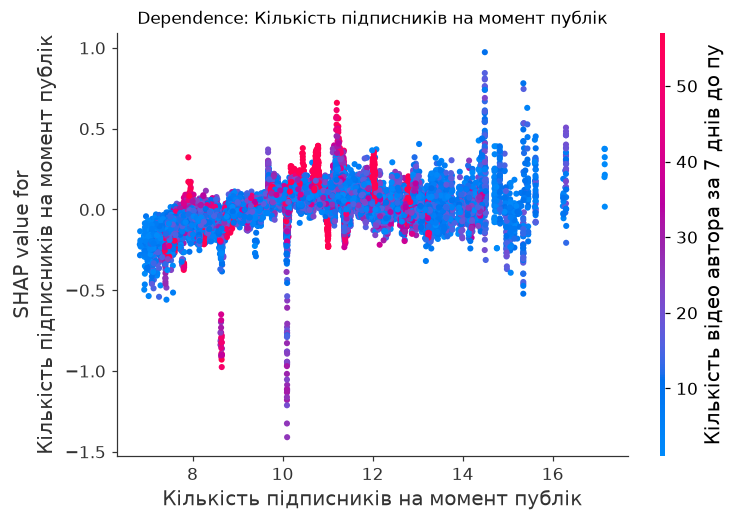

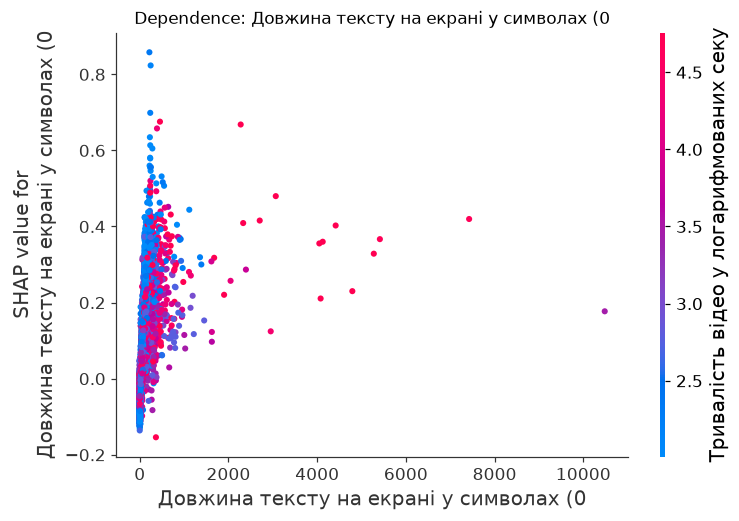

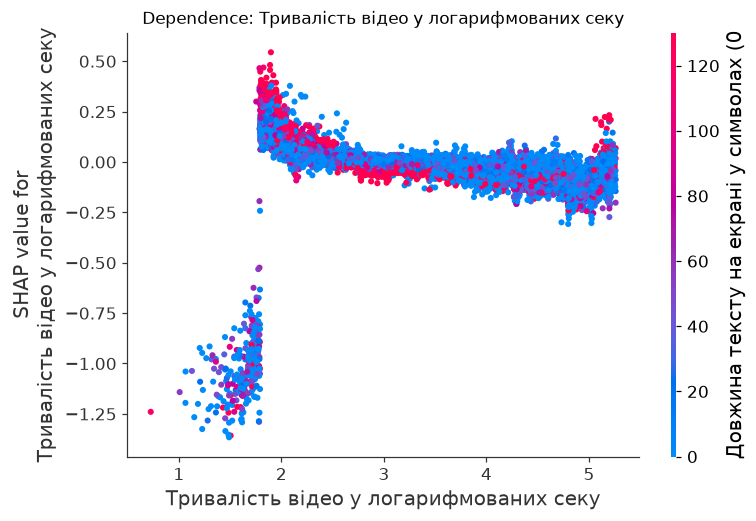

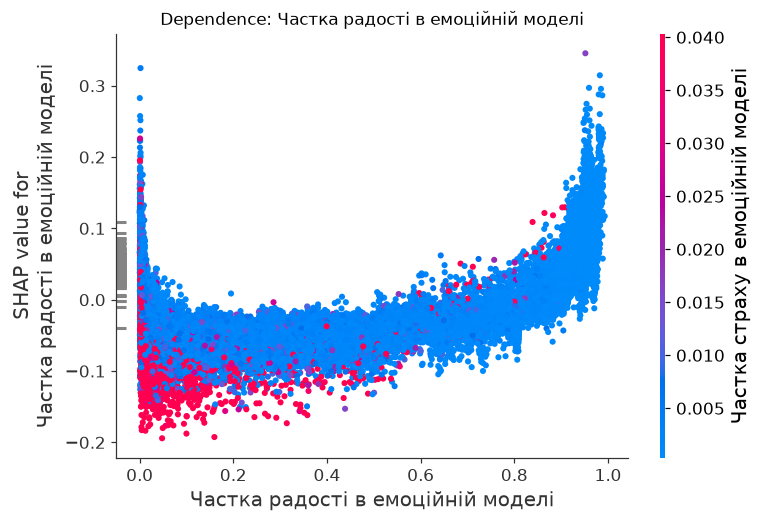

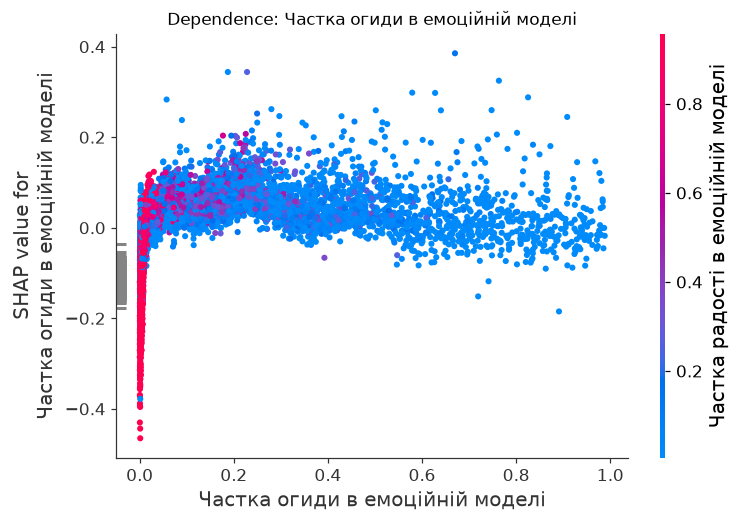

In [5]:
top5_features = global_importance.head(5)["feature"].tolist()

for fname in top5_features:
    if fname not in shap_feat_names:
        continue
    idx   = shap_feat_names.index(fname)
    label = _short_label(fname)
    shap.dependence_plot(
        idx, shap_vals_global, X_test_enc,
        feature_names=shap_labels, show=False,
    )
    plt.title(f"Dependence: {label}", fontsize=11)
    safe = fname.replace("/", "_")
    plt.savefig(FIGS / f"nb07_global_dep_{safe}.png", dpi=110, bbox_inches="tight")
    plt.show()


## 2. Per-Creator Feature Importance (RF Models)

For each of the 1 437 creators we:
1. Load their RF model from `models/per_creator/RF/`.
2. Pass their test videos through the fitted ColumnTransformer.
3. Run `shap.TreeExplainer` and record `mean |SHAP|` per feature.

Creators with fewer than 3 test videos are skipped.
This loop takes roughly 1–3 minutes.


In [6]:
def _compute_creator_shap(author_id):
    path = PC_MODEL_DIR / f"{author_id}.joblib"
    if not path.exists():
        return None
    cm   = CreatorModel.load(path)
    mask = author_test == author_id
    if mask.sum() < 3:
        return None
    X_c  = X_test[mask][cm.feature_names]
    pre  = cm.model.named_steps["pre"]
    mdl  = cm.model.named_steps["mdl"]
    try:
        X_enc          = pre.transform(X_c)
        feat_names_enc = [n.split("__", 1)[-1] for n in pre.get_feature_names_out()]
        expl           = shap.TreeExplainer(mdl)
        sv             = expl.shap_values(X_enc)
        imp            = np.abs(sv).mean(axis=0)
        return {"author_id": author_id, "feat_names": feat_names_enc, "importance": imp}
    except Exception:
        return None

all_authors = sorted(author_test.unique())
print(f"Computing SHAP for {len(all_authors)} creators …")
pc_shap_rows = []
for i, aid in enumerate(all_authors):
    res = _compute_creator_shap(aid)
    if res is None:
        continue
    for fn, iv in zip(res["feat_names"], res["importance"]):
        pc_shap_rows.append({"author_id": aid, "feature": fn, "mean_abs_shap": iv})
    if (i + 1) % 300 == 0:
        print(f"  {i + 1}/{len(all_authors)} …")

pc_shap_df = pd.DataFrame(pc_shap_rows)
pc_shap_df.to_parquet("results/shap_per_creator_importance.parquet", index=False)
n_creators_shap = pc_shap_df["author_id"].nunique()
print(f"Saved results/shap_per_creator_importance.parquet  "
      f"({len(pc_shap_df)} rows, {n_creators_shap} creators)")

# Most important features across all creators (aggregate)
agg = pc_shap_df.groupby("feature")["mean_abs_shap"].mean().sort_values(ascending=False)
print("\nTop 10 features by mean |SHAP| across all creators:")
display(agg.head(10).rename("mean_abs_shap_across_creators").reset_index())


Computing SHAP for 1437 creators …


  300/1437 …


  600/1437 …


  900/1437 …


  1200/1437 …


Saved results/shap_per_creator_importance.parquet  (49436 rows, 1437 creators)

Top 10 features by mean |SHAP| across all creators:


,feature,mean_abs_shap_across_creators
0,video_count_at_publish,0.059240
1,follower_count_log,0.052880
2,duration_log,0.034320
3,desc_len,0.027138
4,sticker_text_len,0.026120
5,sadness,0.024244
6,surprise,0.023913
7,joy,0.022858
8,disgust,0.022624
9,anger,0.022619


### 2.2 Rank Correlation — Creator Recipe vs Global Model

For each creator we rank their features by mean |SHAP|, then compute
Spearman ρ against the global model's ranking (restricted to features
the creator's model includes).

High ρ → creator uses the same "recipe" as the global model.
Low / negative ρ → the driver structure is markedly different.


Creators analysed: 1437
  Median ρ : 0.513
  Mean ρ   : 0.507
  Std ρ    : 0.136
  % ρ > 0.5: 53.4%
  % ρ < 0.0: 0.1%


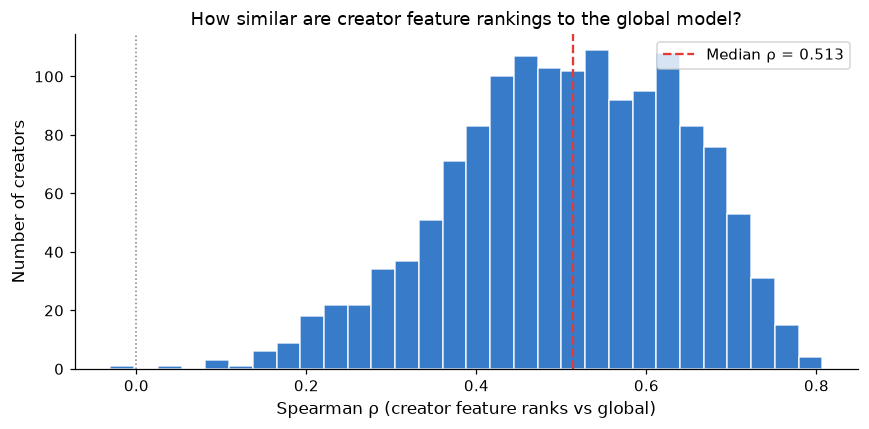


Most frequent features in creators' personal top-5:
  video_count_at_publish          811 creators (  56%)  — Загальна кількість відео автора на момент публікац
  follower_count_log              744 creators (  52%)  — Кількість підписників на момент публікації (log1p,
  duration_log                    540 creators (  38%)  — Тривалість відео у логарифмованих секундах (log1p)
  desc_len                        389 creators (  27%)  — Довжина опису відео у символах (0 якщо опис відсут
  sticker_text_len                367 creators (  26%)  — Довжина тексту на екрані у символах (0 якщо відсут
  sadness                         353 creators (  25%)  — Частка суму в емоційній моделі
  surprise                        350 creators (  24%)  — Частка здивування в емоційній моделі
  videos_last_7d                  316 creators (  22%)  — Кількість відео автора за 7 днів до публікації (не
  disgust                         313 creators (  22%)  — Частка огиди в емоційній моделі
  anger            

In [7]:
global_rank = {
    row.feature: rank
    for rank, row in enumerate(global_importance.itertuples(), 1)
}

rank_rows = []
for aid, grp in pc_shap_df.groupby("author_id"):
    if len(grp) < 3:
        continue
    csorted = grp.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
    c_rank  = {row.feature: rank for rank, row in enumerate(csorted.itertuples(), 1)}
    common  = [f for f in c_rank if f in global_rank]
    if len(common) < 3:
        continue
    cr = [c_rank[f] for f in common]
    gr = [global_rank[f] for f in common]
    rho, _ = spearmanr(cr, gr)
    rank_rows.append({
        "author_id": aid,
        "spearman_vs_global": float(rho),
        "n_features": len(common),
    })

rank_corr_df = pd.DataFrame(rank_rows)
med_rho = rank_corr_df["spearman_vs_global"].median()
print(f"Creators analysed: {len(rank_corr_df)}")
print(f"  Median ρ : {med_rho:.3f}")
print(f"  Mean ρ   : {rank_corr_df['spearman_vs_global'].mean():.3f}")
print(f"  Std ρ    : {rank_corr_df['spearman_vs_global'].std():.3f}")
print(f"  % ρ > 0.5: {(rank_corr_df['spearman_vs_global'] > 0.5).mean()*100:.1f}%")
print(f"  % ρ < 0.0: {(rank_corr_df['spearman_vs_global'] < 0.0).mean()*100:.1f}%")

# Distribution histogram
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(rank_corr_df["spearman_vs_global"], bins=30,
        color="#1565C0", edgecolor="white", alpha=0.85)
ax.axvline(med_rho, color="#E53935", ls="--",
           label=f"Median ρ = {med_rho:.3f}")
ax.axvline(0, color="gray", ls=":", lw=1)
ax.set_xlabel("Spearman ρ (creator feature ranks vs global)", fontsize=11)
ax.set_ylabel("Number of creators", fontsize=11)
ax.set_title("How similar are creator feature rankings to the global model?", fontsize=12)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(FIGS / "nb07_rank_corr_dist.png", dpi=120, bbox_inches="tight")
plt.show()

# Most frequent features in each creator's personal top-5
top5_bag = []
for _, grp in pc_shap_df.groupby("author_id"):
    top5_bag.extend(grp.nlargest(5, "mean_abs_shap")["feature"].tolist())
top5_counts = Counter(top5_bag).most_common(10)
n_cr = rank_corr_df.shape[0]
print("\nMost frequent features in creators' personal top-5:")
for feat, cnt in top5_counts:
    pct = cnt / n_cr * 100
    lbl = FEATURE_DESCRIPTIONS.get(feat, feat)[:50]
    print(f"  {feat:<30} {cnt:4d} creators ({pct:4.0f}%)  — {lbl}")


## 3. Stability Analysis — Are Top-3 Features Reliable?

Creators with 24–50 training videos have highly uncertain models; a different
random sample from the same creator might surface different "top features."

We quantify this with **bootstrap retraining**: for a stratified sample of
~25 creators (5 per size bin), we resample their training data 15 times, retrain
the RF model (30 trees for speed), and record which 3 features have the highest
mean |SHAP|.

**Stability score** = fraction of 15 bootstraps where top-3 matches the modal top-3.
Score 1.0 = always the same 3 features; 0.0 = never.

> ⚠️  This uses 30 trees instead of the production 100 for speed; results are
> directionally correct but slightly noisier.


In [8]:
RF_STAB_CFG = {"n_estimators": 30, "max_depth": 4, "min_samples_leaf": 5, "max_features": 0.4}
N_BOOT           = 15
N_SAMPLE_PER_BIN = 5

pc_meta = pd.read_parquet("results/per_creator_metrics_percreator.parquet")

rng = np.random.RandomState(SEED)
sample_parts = []
for bin_name, grp in pc_meta.groupby("size_bin"):
    eligible = grp[grp["author_id"].isin(rank_corr_df["author_id"])]
    n        = min(N_SAMPLE_PER_BIN, len(eligible))
    sample_parts.append(eligible.sample(n, random_state=SEED))
sample_meta = pd.concat(sample_parts, ignore_index=True)
print(f"Stability sample: {len(sample_meta)} creators  "
      f"(bins: {dict(sample_meta['size_bin'].value_counts())})")

def _boot_stability(author_id, n_boot=N_BOOT, seed=SEED):
    mask = (author_train == author_id).values
    X_c  = X_train.iloc[mask]
    y_c  = y_train.iloc[mask]
    if len(X_c) < 10:
        return float("nan")
    rng_b     = np.random.RandomState(seed)
    top3_list = []
    for _ in range(n_boot):
        idx    = rng_b.choice(len(X_c), size=len(X_c), replace=True)
        X_b    = X_c.iloc[idx].reset_index(drop=True)
        y_b    = y_c.iloc[idx].reset_index(drop=True)
        X_cln, _ = drop_constant_features(X_b)
        if X_cln.shape[1] == 0 or len(X_cln) < 6:
            continue
        try:
            pipe     = _make_creator_pipe(X_cln, "rf", RF_STAB_CFG, seed=seed)
            pipe.fit(X_cln, y_b.values)
            pre      = pipe.named_steps["pre"]
            mdl      = pipe.named_steps["mdl"]
            X_enc    = pre.transform(X_cln)
            fn_enc   = [n.split("__", 1)[-1] for n in pre.get_feature_names_out()]
            expl     = shap.TreeExplainer(mdl)
            sv       = expl.shap_values(X_enc)
            imp      = np.abs(sv).mean(axis=0)
            top3     = frozenset(np.array(fn_enc)[np.argsort(imp)[::-1][:3]])
            top3_list.append(top3)
        except Exception:
            continue
    if len(top3_list) < 2:
        return float("nan")
    modal    = Counter(top3_list).most_common(1)[0][0]
    return sum(1 for t in top3_list if t == modal) / len(top3_list)

stab_rows = []
for _, row in sample_meta.iterrows():
    aid  = row["author_id"]
    stab = _boot_stability(aid)
    stab_rows.append({
        "author_id": aid,
        "n_train":   row["n_train"],
        "size_bin":  row["size_bin"],
        "stability": stab,
    })
    print(f"  {aid[:12]}  n_train={row['n_train']:4d}  size_bin={row['size_bin']}  "
          f"stability={stab:.2f}" if not np.isnan(stab) else
          f"  {aid[:12]}  n_train={row['n_train']:4d}  size_bin={row['size_bin']}  stability=NaN")

stability_df = pd.DataFrame(stab_rows).dropna(subset=["stability"])
print("\nStability by size bin:")
display(stability_df.groupby("size_bin")["stability"].describe().round(3))


Stability sample: 25 creators  (bins: {'24-50': np.int64(5), '51-100': np.int64(5), '101-200': np.int64(5), '201-500': np.int64(5), '500+': np.int64(5)})


  687704960568  n_train=  44  size_bin=24-50  stability=0.07


  2364263  n_train=  27  size_bin=24-50  stability=0.13


  690839444725  n_train=  24  size_bin=24-50  stability=0.13


  690368171470  n_train=  26  size_bin=24-50  stability=0.13


...

  682560741871  n_train= 825  size_bin=500+  stability=0.40


  154071737528  n_train= 591  size_bin=500+  stability=0.40


  682510044082  n_train=1366  size_bin=500+  stability=0.40


  693006776313  n_train= 530  size_bin=500+  stability=0.13

Stability by size bin:


,count,mean,std,min,25%,50%,75%,max
size_bin,,,,,,,,
101-200,5.0,0.227,0.089,0.133,0.133,0.267,0.267,0.333
201-500,5.0,0.347,0.344,0.067,0.133,0.267,0.333,0.933
24-50,5.0,0.107,0.037,0.067,0.067,0.133,0.133,0.133
500+,5.0,0.453,0.292,0.133,0.400,0.400,0.400,0.933
51-100,5.0,0.280,0.110,0.200,0.200,0.267,0.267,0.467


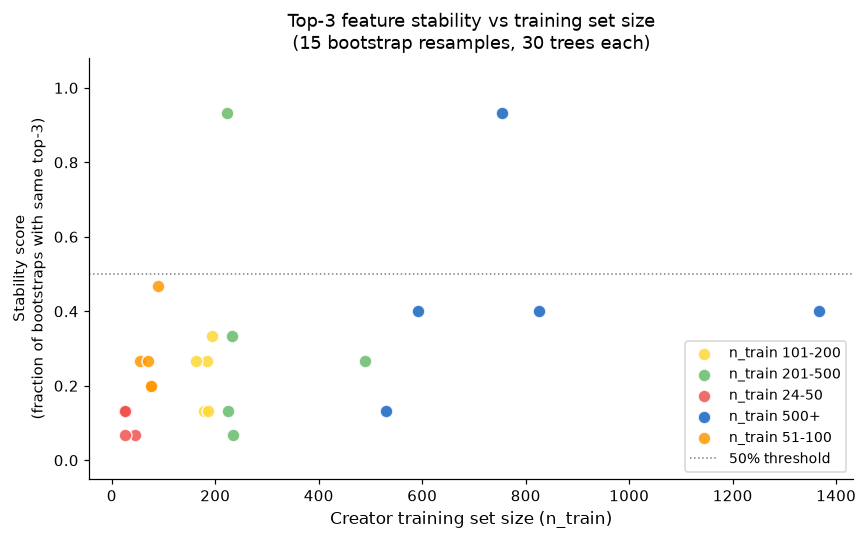

Median stability — small creators  (24–50):    0.13
Median stability — large creators  (200+):     0.37


In [9]:
bin_colors = {
    "24-50":   "#EF5350",
    "51-100":  "#FF9800",
    "101-200": "#FDD835",
    "201-500": "#66BB6A",
    "500+":    "#1565C0",
}
fig, ax = plt.subplots(figsize=(8, 5))
for bname, grp in stability_df.groupby("size_bin"):
    ax.scatter(grp["n_train"], grp["stability"],
               c=bin_colors.get(bname, "gray"), label=f"n_train {bname}",
               s=70, alpha=0.85, edgecolor="white", zorder=3)
ax.axhline(0.5, color="gray", ls=":", lw=1, label="50% threshold")
ax.set_xlabel("Creator training set size (n_train)", fontsize=11)
ax.set_ylabel("Stability score\n(fraction of bootstraps with same top-3)", fontsize=10)
ax.set_title("Top-3 feature stability vs training set size\n(15 bootstrap resamples, 30 trees each)", fontsize=12)
ax.legend(fontsize=9, loc="lower right")
ax.set_ylim(-0.05, 1.08)
plt.tight_layout()
plt.savefig(FIGS / "nb07_stability.png", dpi=120, bbox_inches="tight")
plt.show()

bins_small = ["24-50"]
bins_large = ["201-500", "500+"]
med_small = stability_df[stability_df["size_bin"].isin(bins_small)]["stability"].median()
med_large = stability_df[stability_df["size_bin"].isin(bins_large)]["stability"].median()
print(f"Median stability — small creators  (24–50):    {med_small:.2f}")
print(f"Median stability — large creators  (200+):     {med_large:.2f}")


## 4. Case Studies: Creator A / B / C

We pick one representative creator from each scale group and compare their
SHAP feature importance against the global model.

| Label | Group | n_train range |
|-------|-------|--------------|
| **Creator A** | small  | 24–50 |
| **Creator B** | medium | 101–200 |
| **Creator C** | large  | 201+ |

Creators are identified only by their anonymous label.
No individual transcripts or profile details are cited.


Case study creators:
  Creator A (small): n_train=24, n_test=6, size_bin=24-50
  Creator B (medium): n_train=101, n_test=25, size_bin=101-200
  Creator C (large): n_train=506, n_test=126, size_bin=500+

Creator A (small)  (n_train=24, n_test=6)
  Creator top-3 : ['speaking_rate', 'duration_log', 'disgust']
  Global top-3  : ['follower_count_log', 'sticker_text_len', 'duration_log']
  Overlap       : 1/3
  Spearman ρ vs global: 0.443


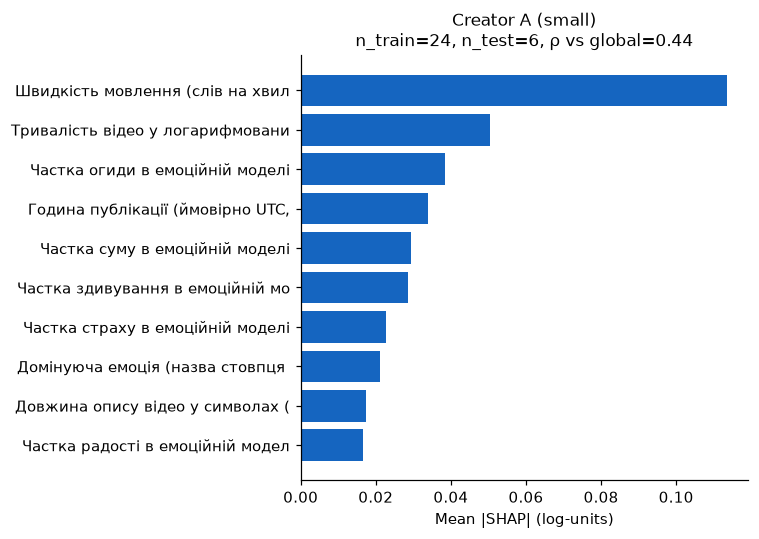


Creator B (medium)  (n_train=101, n_test=25)
  Creator top-3 : ['disgust', 'surprise', 'joy']
  Global top-3  : ['follower_count_log', 'sticker_text_len', 'duration_log']
  Overlap       : 0/3
  Spearman ρ vs global: 0.302


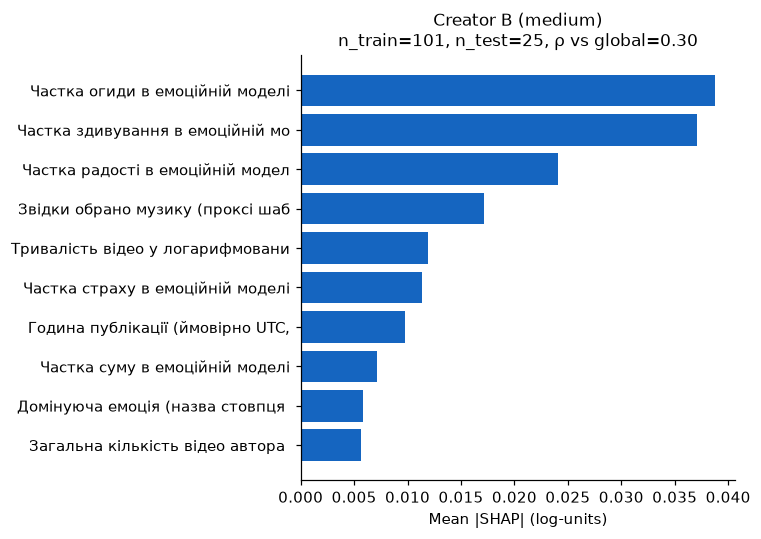


Creator C (large)  (n_train=506, n_test=126)
  Creator top-3 : ['video_count_at_publish', 'sticker_text_len', 'desc_len']
  Global top-3  : ['follower_count_log', 'sticker_text_len', 'duration_log']
  Overlap       : 1/3
  Spearman ρ vs global: 0.630


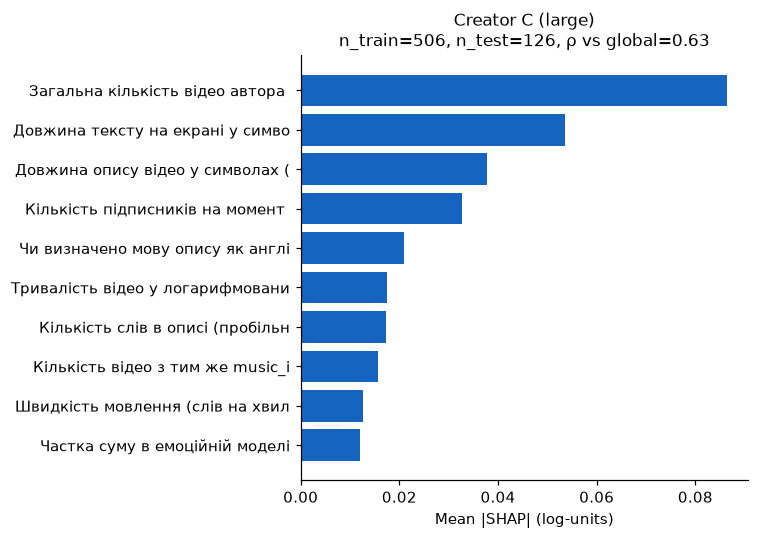

In [10]:
def _pick_creator_for_case(size_bin, min_test=5):
    cands = pc_meta[pc_meta["size_bin"] == size_bin].sort_values("n_train")
    for _, row in cands.iterrows():
        aid = row["author_id"]
        if aid not in rank_corr_df["author_id"].values:
            continue
        if (author_test == aid).sum() >= min_test:
            return aid
    return None

case_creators = {
    "Creator A (small)":  _pick_creator_for_case("24-50"),
    "Creator B (medium)": _pick_creator_for_case("101-200"),
    "Creator C (large)":  _pick_creator_for_case("500+") or _pick_creator_for_case("201-500"),
}
print("Case study creators:")
for lbl, aid in case_creators.items():
    if aid:
        r = pc_meta[pc_meta["author_id"] == aid].iloc[0]
        print(f"  {lbl}: n_train={r['n_train']}, n_test={r['n_test']}, size_bin={r['size_bin']}")
    else:
        print(f"  {lbl}: NOT FOUND")

def _case_plot(label, author_id):
    if not author_id:
        print(f"  {label}: skipped (no creator found)")
        return
    path = PC_MODEL_DIR / f"{author_id}.joblib"
    if not path.exists():
        print(f"  {label}: model file not found")
        return
    cm   = CreatorModel.load(path)
    mask = author_test == author_id
    X_c  = X_test[mask][cm.feature_names]
    pre  = cm.model.named_steps["pre"]
    mdl  = cm.model.named_steps["mdl"]
    try:
        X_enc  = pre.transform(X_c)
        fn_enc = [n.split("__", 1)[-1] for n in pre.get_feature_names_out()]
        expl   = shap.TreeExplainer(mdl)
        sv     = expl.shap_values(X_enc)
    except Exception as e:
        print(f"  {label}: SHAP error — {e}")
        return
    imp      = np.abs(sv).mean(axis=0)
    top10_i  = np.argsort(imp)[::-1][:10]
    top3_c   = [fn_enc[i] for i in top10_i[:3]]
    top3_g   = global_importance.head(3)["feature"].tolist()
    overlap  = len(set(top3_c) & set(top3_g))
    rho_rows = rank_corr_df[rank_corr_df["author_id"] == author_id]
    rho_val  = rho_rows["spearman_vs_global"].values[0] if len(rho_rows) else float("nan")
    r        = pc_meta[pc_meta["author_id"] == author_id].iloc[0]

    print(f"\n{label}  (n_train={r['n_train']}, n_test={r['n_test']})")
    print(f"  Creator top-3 : {top3_c}")
    print(f"  Global top-3  : {top3_g}")
    print(f"  Overlap       : {overlap}/3")
    print(f"  Spearman ρ vs global: {rho_val:.3f}")

    labels_top10 = [_short_label(fn_enc[i], maxlen=32) for i in top10_i]
    imp_top10    = imp[top10_i]
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.barh(labels_top10[::-1], imp_top10[::-1], color="#1565C0")
    ax.set_xlabel("Mean |SHAP| (log-units)", fontsize=10)
    ax.set_title(
        f"{label}\nn_train={r['n_train']}, n_test={r['n_test']},"
        f" ρ vs global={rho_val:.2f}",
        fontsize=11,
    )
    plt.tight_layout()
    safe = label.split(" ")[1].lower()
    plt.savefig(FIGS / f"nb07_case_{safe}.png", dpi=110, bbox_inches="tight")
    plt.show()

for lbl, aid in case_creators.items():
    _case_plot(lbl, aid)


## 5. Save Results


In [11]:
from creator_analytics.evaluate import log_experiment

# Merge stability with per-creator meta for downstream use
explain_summary = rank_corr_df.merge(
    pc_meta[["author_id", "n_train", "size_bin"]], on="author_id", how="left"
)
explain_summary.to_parquet("results/shap_rank_corr.parquet", index=False)
stability_df.to_parquet("results/shap_stability.parquet", index=False)
print("Saved results/shap_rank_corr.parquet  "
      f"({len(explain_summary)} rows)")
print("Saved results/shap_stability.parquet  "
      f"({len(stability_df)} rows)")

top3 = global_importance.head(3)["feature"].tolist()
med_rho = rank_corr_df["spearman_vs_global"].median()

log_experiment(
    path="results/experiments.md",
    name="SHAP_explainability",
    date="2026-10-19",
    features="all_53",
    model="XGBoost_SHAP",
    params={"shap_version": shap.__version__, "n_test": int(X_test.shape[0])},
    cv_rmse=None,
    test_metrics={"rmse": 0.0, "r2": 0.0, "spearman": 0.0},
    comment=(
        f"global_top3={','.join(top3)}; "
        f"median_rank_corr={med_rho:.3f}; "
        f"n_creators_shap={len(rank_corr_df)}"
    ),
)
print("Updated results/experiments.md")


Saved results/shap_rank_corr.parquet  (1437 rows)
Saved results/shap_stability.parquet  (25 rows)
Updated results/experiments.md


## Summary

Three headline results:
1. Which features matter most **globally**.
2. How much creators **differ** in their feature importance rankings.
3. Whether per-creator top-3 features are **stable** under resampling.


In [12]:
top3_names  = global_importance.head(3)["feature"].tolist()
top3_vals   = global_importance.head(3)["mean_abs_shap"].tolist()
med_rho     = rank_corr_df["spearman_vs_global"].median()
pct_low_rho = (rank_corr_df["spearman_vs_global"] < 0.3).mean() * 100

print("=" * 70)
print("NB07 — SHAP Explainability Summary")
print("=" * 70)

print("\n1. Global model — top 3 features (mean |SHAP|):")
for i, (feat, val) in enumerate(zip(top3_names, top3_vals), 1):
    lbl = _short_label(feat)
    print(f"   {i}. {feat:<30} {val:.4f}  — {lbl}")

print(f"\n2. Creator recipe diversity ({len(rank_corr_df)} creators):")
print(f"   Median Spearman ρ vs global = {med_rho:.3f}")
print(f"   Fraction with ρ < 0.3       = {pct_low_rho:.0f}%")
if med_rho > 0.4:
    print("   → Most creators broadly agree on which features matter.")
else:
    print("   → Considerable diversity in creator feature importance rankings.")

if len(stability_df) > 0:
    bins_small = ["24-50"]
    bins_large = ["201-500", "500+"]
    ms = stability_df[stability_df["size_bin"].isin(bins_small)]["stability"].median()
    ml = stability_df[stability_df["size_bin"].isin(bins_large)]["stability"].median()
    print(f"\n3. Feature stability (15 bootstraps, 30 trees):")
    print(f"   Small creators  (24–50 train videos):  median stability = {ms:.2f}")
    print(f"   Large creators  (200+ train videos):   median stability = {ml:.2f}")
    if not (np.isnan(ms) or np.isnan(ml)):
        if ml - ms > 0.2:
            print("   → Top-3 features are substantially more stable for large creators.")
        elif ml - ms > 0.05:
            print("   → Modest stability advantage for large creators.")
        else:
            print("   → Stability is similar across creator sizes in this sample.")
    print("   ⚠️  Small-creator importance rankings should be interpreted with caution.")

print()
print("Figures: results/figures/nb07_*.png")
print("SHAP values: results/shap_global_test.parquet")
print("Per-creator importance: results/shap_per_creator_importance.parquet")


NB07 — SHAP Explainability Summary

1. Global model — top 3 features (mean |SHAP|):
   1. follower_count_log             0.0746  — Кількість підписників на момент публік
   2. sticker_text_len               0.0662  — Довжина тексту на екрані у символах (0
   3. duration_log                   0.0494  — Тривалість відео у логарифмованих секу

2. Creator recipe diversity (1437 creators):
   Median Spearman ρ vs global = 0.513
   Fraction with ρ < 0.3       = 8%
   → Most creators broadly agree on which features matter.

3. Feature stability (15 bootstraps, 30 trees):
   Small creators  (24–50 train videos):  median stability = 0.13
   Large creators  (200+ train videos):   median stability = 0.37
   → Top-3 features are substantially more stable for large creators.
   ⚠️  Small-creator importance rankings should be interpreted with caution.

Figures: results/figures/nb07_*.png
SHAP values: results/shap_global_test.parquet
Per-creator importance: results/shap_per_creator_importance.parquet